In [1]:
# Instale através do requirements.txt: pip install -r requirements.txt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as skl
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Input
from keras.callbacks import EarlyStopping
from keras import regularizers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from keras.optimizers import Adam

I0000 00:00:1795215039.096941    2507 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795215040.189291    2507 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795215043.784888    2507 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
df = pd.read_csv('../data/base-sintetica.txt', 
                 sep='\t', 
                 comment='#', 
                 header=None, 
                 names=['x1', 'x2', 'target'])

In [3]:
X = df.drop(columns=['target'])
y = df['target'] - 1

X_train, X_test, y_train, y_test = skl.model_selection.train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_reg = Sequential(
    [
        Input(shape=(X_train_scaled.shape[1],)),
        Dense(8, activation='relu'),
        Dense(15, activation='softmax')
    ]
)

model_reg.compile(
    optimizer=Adam(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_reg.summary()


E0000 00:00:1795215051.626771    2507 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │           135 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 159 (636.00 B)

 Trainable params: 159 (636.00 B)

 Non-trainable params: 0 (0.00 B)

In [4]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

history = model_reg.fit(
    X_train_scaled,
    y_train,
    batch_size=16,
    epochs=100,
    validation_split=0.2,
    verbose=1,
    callbacks=[early_stop]
)

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1536 - loss: 2.6411 - val_accuracy: 0.1250 - val_loss: 2.4696
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1979 - loss: 2.2055 - val_accuracy: 0.1771 - val_loss: 2.2149
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3177 - loss: 1.8463 - val_accuracy: 0.2604 - val_loss: 1.9037
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3724 - loss: 1.5065 - val_accuracy: 0.4167 - val_loss: 1.5459
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6484 - loss: 1.1923 - val_accuracy: 0.6354 - val_loss: 1.2159
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7891 - loss: 0.9482 - val_accuracy: 0.7396 - val_loss: 0.9712
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8620 - loss: 0.7683 - val_accuracy: 0.8646 - val_loss: 0.7928
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9583 - loss: 0.6258 - val_accuracy: 0.9479 - 

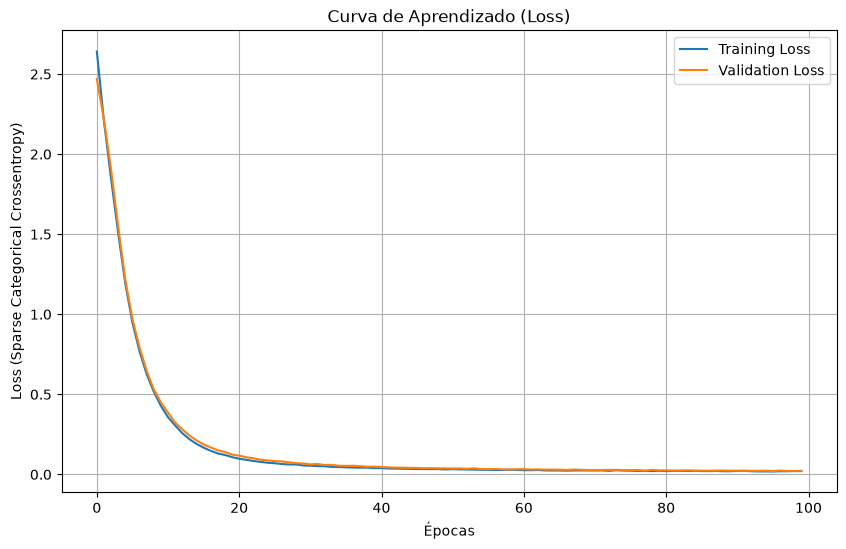

In [5]:
plt.figure(figsize=(10, 6))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Curva de Aprendizado (Loss)')
plt.xlabel('Épocas')
plt.ylabel('Loss (Sparse Categorical Crossentropy)')
plt.legend()
plt.grid(True)
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Relatório de Classificação (Classes 0 a 14):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00         8
           3       1.00      1.00      1.00         8
           4       1.00      1.00      1.00         8
           5       1.00      1.00      1.00         8
           6       1.00      1.00      1.00         8
           7       1.00      1.00      1.00         8
           8       1.00      1.00      1.00         8
           9       1.00      1.00      1.00         8
          10       1.00      1.00      1.00         8
          11       1.00      1.00      1.00         8
          12       1.00      1.00      1.00         8
          13       1.00      1.00      1.00         8
          14       1.00      1.00      1.00         8

    accuracy                           1.00       1

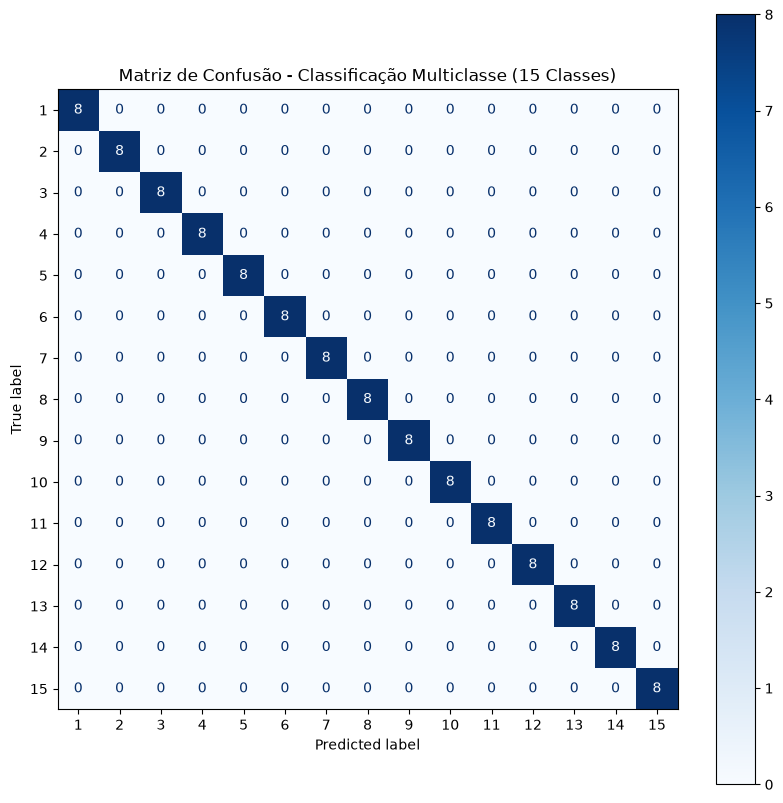

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# gera probabilidades para as 15 classes e seleciona a de maior valor
y_pred_prob = model_reg.predict(X_test_scaled)
y_pred = np.argmax(y_pred_prob, axis=1)

# exibe relatório completo (Precision, Recall/Sensitivity, F1-Score e Accuracy)
print("Relatório de Classificação (Classes 0 a 14):")
print(classification_report(y_test, y_pred))

# calcula e plota a matriz de confusão 15x15
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(1, 16))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Matriz de Confusão - Classificação Multiclasse (15 Classes)')
plt.show()